# 1. Input posteriors

This is the first of three notebooks that reproduce the results of *Combining the Mass–Radius Posteriors of PSR J0030+0451 Allowing for Unknown Model Systematics*

This notebook provides a demonstration of how we load data from each of the eight analyses incorporated into our combination.
The notebook runs, as all three notebooks do, from the repository root and imports the small `j0030` package which holds the computational method.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from j0030 import method, plotting

## Summary of the inputs

Each file in `data/` holds posterior samples published by the original analysis, as two columns: gravitational mass $M$ (in $M_\odot$) and equatorial radius $R$ (in km). See the README for sources and citations.

| Key | Paper | Hot-spot model |
|---|---|---|
| `ST_PST19` | Riley et al. (2019) | ST+PST |
| `ST_PDT`, `ST_PST`, `PDT_U`, `ST_U` | Vinciguerra et al. (2024) | ST+PDT, ST+PST, PDT-U, ST-U |
| `2spot`, `3spot` | Miller et al. (2019) | two and three oval spots |
| `PDT_U26` | Kini et al. (2026) | PDT-U |

All eight models come from NICER data of PSR J0030+0451, but modeling choices regarding the hotspot configurations and background emission cause eight distinct predicitons of $M$, $R$ and $C$. Medians and central 68% intervals of each parameter are shown below, computed directly from the samples (See Table 1 of the paper).

In [9]:
samples = {key: method.load_samples(key) for key in method.MODEL_KEYS}

print(f"{'input':<24}{'samples':>9}{'M (Msun)':>20}{'R (km)':>21}{'C':>23}")
for key, (M, R) in samples.items():
    C = method.K_KM * M / R
    print(f"{method.label(key):<24}{len(M):>9}"
          f"{method.fmt(method.sample_quantiles(M), 2):>20}"
          f"{method.fmt(method.sample_quantiles(R), 2):>21}"
          f"{method.fmt(method.sample_quantiles(C), 3):>23}")

input                     samples            M (Msun)               R (km)                      C
Riley19: ST+PST              7852    1.29 +0.17/-0.16    12.57 +1.37/-1.29    0.153 +0.011/-0.014
Vinciguerra24: ST+PDT       12008    1.40 +0.13/-0.12    11.71 +0.87/-0.83    0.177 +0.006/-0.007
Vinciguerra24: ST+PST       11795    1.93 +0.10/-0.12    15.23 +0.52/-0.84    0.188 +0.006/-0.007
Vinciguerra24: PDT-U        12832    1.70 +0.18/-0.19    14.44 +0.88/-1.05    0.179 +0.011/-0.022
Vinciguerra24: ST-U         69355    1.88 +0.13/-0.19    15.12 +0.64/-1.31    0.186 +0.007/-0.010
Miller19: 2spot            400000    1.44 +0.17/-0.16    13.27 +1.30/-1.15    0.160 +0.009/-0.008
Miller19: 3spot           1000000    1.44 +0.15/-0.15    13.01 +1.25/-1.06    0.163 +0.008/-0.009
Kini26: PDT-U              168884    1.43 +0.20/-0.17    12.68 +1.31/-1.04    0.169 +0.011/-0.014


## Mass–radius and mass–compactness space

The primary constraint of pulse-profile modelling is the relationship between $M$ and $R$, i.e. the compactness $C$. For this reason, the input posteriors in $M$--$R$ space appear stretched along lines of constant conpactness (the combination in notebook 2 is carried out in $(M, C)$ rather than $(M, R)$ to preserve this crucial feature of the data).

Shown below are the contours of the eight input psoteriors in both $(M, R)$ and $(M, C)$ space, with 68% and 95% credible regions. Samples from each analysis are limited to a maximum of 50,000, but plotting here can still take up to a minute.

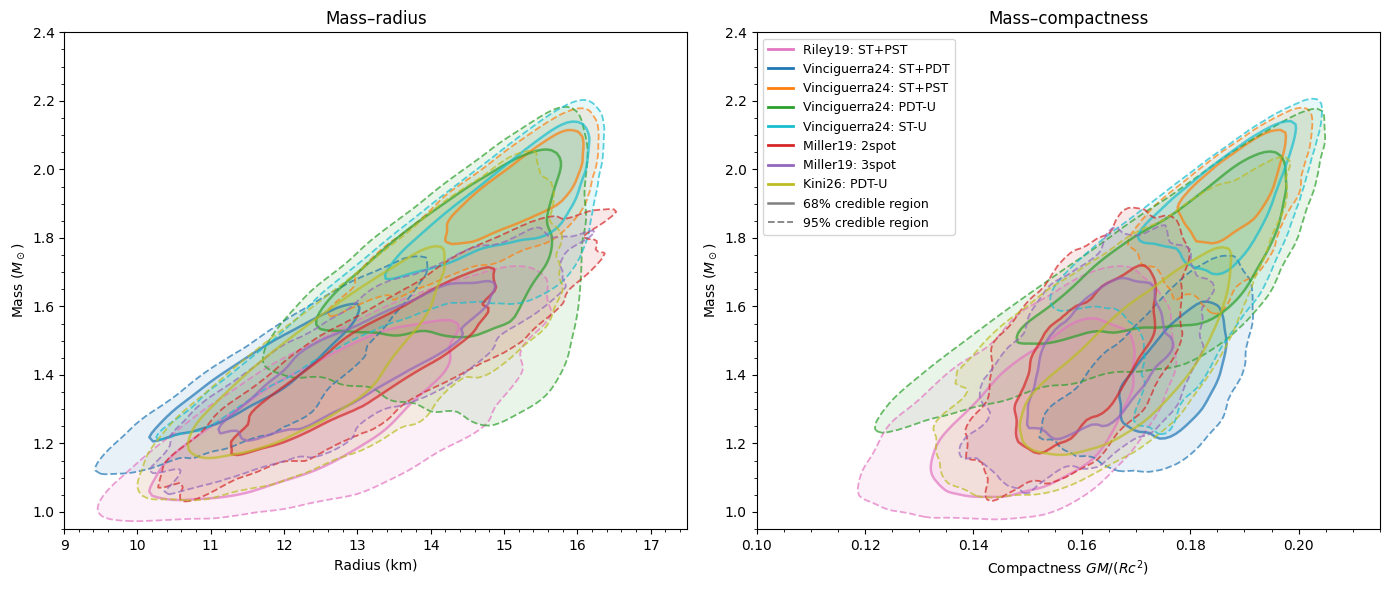

In [11]:
# Silverman KDE of each input, drawn as 68% (solid) and 95% (dashed) credible regions,
# in the same style as the paper's figures. Inputs with more than 50,000 samples are
# thinned to 50,000 before the KDE, which only affects the display.
rng = np.random.default_rng(0)
M_disp, R_disp = np.linspace(0.95, 2.4, 120), np.linspace(9.0, 17.5, 120)
C_disp = np.linspace(0.10, 0.215, 120)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
handles = []
for key, (M, R) in samples.items():
    idx = rng.choice(len(M), size=min(len(M), 50_000), replace=False)
    M, R = M[idx], R[idx]
    color = method.MODELS[key]["color"]
    MR = plotting.kde_on_grid(np.vstack([M, R]), M_disp, R_disp)
    MC = plotting.kde_on_grid(np.vstack([M, method.K_KM * M / R]), M_disp, C_disp)
    plotting.draw_hdr(ax1, R_disp, M_disp, MR, color, (0.10, 0.20))
    plotting.draw_hdr(ax2, C_disp, M_disp, MC, color, (0.10, 0.20))
    handles.append(plt.Line2D([], [], color=color, lw=2, label=method.label(key)))
handles += [plt.Line2D([], [], color="gray", lw=1.8, ls="-", label="68% credible region"),
            plt.Line2D([], [], color="gray", lw=1.3, ls="--", label="95% credible region")]
for ax in (ax1, ax2):
    ax.set_ylabel(r"Mass ($M_\odot$)")
    ax.minorticks_on()
ax1.set(xlabel="Radius (km)", title="Mass–radius")
ax2.set(xlabel=r"Compactness $GM/(Rc^2)$", title="Mass–compactness")
ax2.legend(handles=handles, fontsize=9, loc="upper left")
plt.tight_layout()

In the second notebook, **`2_Combined_Posterior.ipynb`**, we'll execute the main stage of this method: combining these eight posteriors into a single coherent estimate of J0030's parameters. Crucially, our method will take into account the unknown systematics that could bias individual posteriors or the entire ensemble.